# 01 · Batch DWH: từ CSV đến kho Parquet

Notebook này dựng tầng batch của kho dữ liệu:

1. Nạp 4 file CSV thật vào DuckDB.
2. Làm sạch, kiểm tra chất lượng và tạo bảng chiều / bảng sự kiện.
3. Ghi **Parquet phân vùng Hive-style** (`year=YYYY/month=MM/`).
4. Chạy 4 truy vấn tương đương bài báo và đo thời gian.

> **Engine lite:** DuckDB thay cho Hive/Spark, local filesystem thay cho HDFS. Các khái niệm partition, Parquet, star schema và benchmark vẫn giữ nguyên. Xem `README.md` để biết ánh xạ và cách chuyển sang Spark/Hive khi có Docker.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import *
ensure_dirs()
setup_matplotlib()

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from warehouse import (
    connect, reset_database_file, create_base_tables, table_summary,
    data_quality_report, write_parquet_lake, run_benchmark,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
print("ROOT:", ROOT)


ROOT: D:\projectDW\agri-dwh


## 1. Tạo database và nạp dữ liệu

Database được tạo lại từ đầu để notebook có thể chạy lặp lại. Bốn bảng gốc: `dim_location`, `fact_weather_hourly`, `fact_weather_daily`, `fact_cereal_annual`; thêm `dim_date`.


In [2]:
reset_database_file()
con = connect()
create_base_tables(con)

summary = table_summary(con)
summary.to_csv(REPORTS_DIR / "table_summary.csv", index=False)
display(summary.style.format({"rows": "{:,}"}))


,table,rows
0,dim_location,12
1,fact_weather_hourly,"1,052,064"
2,fact_weather_daily,"43,836"
3,fact_cereal_annual,100
4,dim_date,"3,653"


## 2. Data quality gate

Các kiểm tra dưới đây là điều kiện để pipeline batch được coi là thành công. Nếu một dòng FAIL, không nên chạy tiếp sang ML.


In [3]:
quality = data_quality_report(con)
quality.to_csv(REPORTS_DIR / "data_quality.csv", index=False)
display(quality)


,Kiểm tra,Giá trị,Kết quả
0,Số dòng hourly,"1,052,064",PASS
1,"Duplicate (location_id, event_time)",0,PASS
2,Null ở 3 biến chính,0,PASS
3,Nhiệt độ hourly (°C),-32.9 … 48.5,PASS
4,Độ ẩm đất (0–1),0.24 … 1.00,PASS
5,Số địa điểm,12,PASS
6,Số partition year-month,120,PASS
7,View benchmark join được,"1,052,064",PASS


## 3. Ghi Parquet phân vùng

Mỗi năm/tháng là một thư mục. Đây là cách Hive/Spark thường tổ chức dữ liệu trên HDFS; ở đây cùng cấu trúc được ghi xuống local filesystem. View `fact_weather_hourly_lake` đọc lại các file này với `hive_partitioning=true`.


In [4]:
lake = write_parquet_lake(con)
display(pd.DataFrame([lake]).style.format({"lake_rows": "{:,}"}))
display(con.execute("SELECT * FROM fact_weather_hourly_lake LIMIT 4").df())


,parquet_dir,partition_files,lake_rows
0,D:\projectDW\agri-dwh\warehouse\parquet\fact_weather_hourly,120,"1,052,064"


,event_time,location_id,t2m_c,rh2m_pct,precip_mm_h,ws2m_ms,soil_wetness_root,soil_wetness_top,month,year
0,2015-01-27 13:00:00,VN-CT,34.55,34.17,0.0,2.52,0.54,0.44,1,2015
1,2015-01-27 15:00:00,VN-CT,33.98,34.41,0.0,2.25,0.53,0.43,1,2015
2,2015-01-29 16:00:00,VN-CT,33.38,36.52,0.0,2.50,0.53,0.42,1,2015
3,2015-01-02 14:00:00,VN-HD,21.31,51.70,0.0,2.80,0.68,0.68,1,2015


## 4. Bốn truy vấn benchmark

Bốn loại truy vấn giống bài báo: đếm dòng, tổng hợp theo nhóm, lọc + tổng hợp, và sắp xếp top 10. Mỗi truy vấn chạy trên 100.000 dòng và toàn bộ 1.052.064 dòng; thời gian là median của 3 lần chạy sau một lần warm-up.


In [5]:
bench = run_benchmark(con)
bench.to_csv(REPORTS_DIR / "benchmark_results.csv", index=False)
display(bench.style.format({"seconds_median": "{:.4f}", "scale": "{:,}"}))


,scale,query,seconds_median,result_rows
0,"100,000",Đếm toàn bộ dòng,0.0006,1
1,"100,000",Năng suất TB theo khu,0.0096,12
2,"100,000",Độ ẩm TB khi nhiệt > 25,0.0075,11
3,"100,000",Top 10 theo năng suất,0.0050,10
4,"1,052,064",Đếm toàn bộ dòng,0.0005,1
5,"1,052,064",Năng suất TB theo khu,0.0071,12
6,"1,052,064",Độ ẩm TB khi nhiệt > 25,0.0055,12
7,"1,052,064",Top 10 theo năng suất,0.0028,10


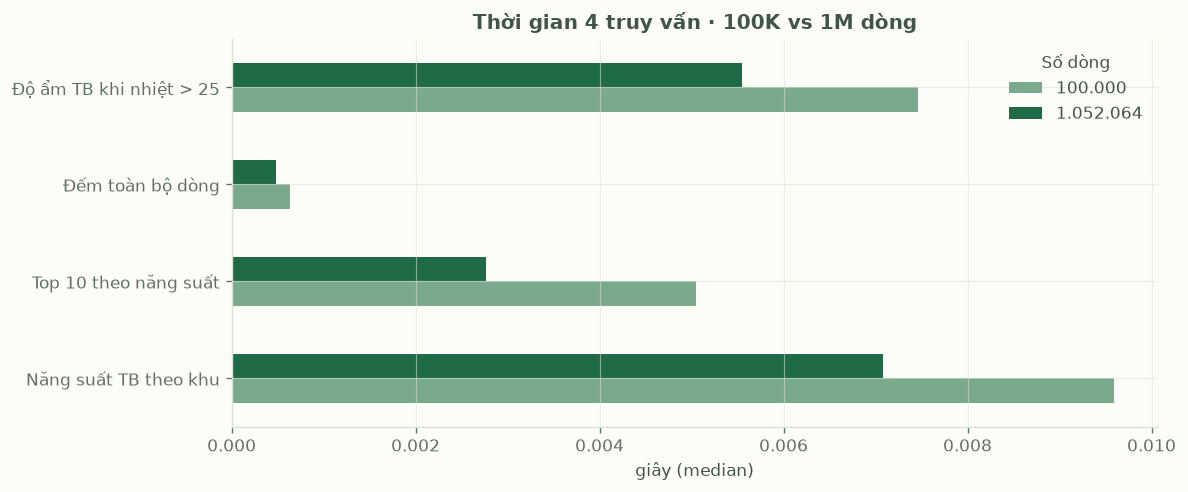

In [6]:
pivot = bench.pivot(index="query", columns="scale", values="seconds_median")
fig, ax = plt.subplots(figsize=(10, 4.2))
pivot.plot(kind="barh", ax=ax, color=[PALETTE["green_light"], PALETTE["green"]])
ax.set_xlabel("giây (median)")
ax.set_ylabel("")
ax.set_title("Thời gian 4 truy vấn · 100K vs 1M dòng")
ax.legend(title="Số dòng", labels=["100.000", "1.052.064"])
fig.tight_layout()
save_figure(fig, "01_benchmark.png")
plt.show()


## 5. Xem kết quả thật của 4 truy vấn

Không chỉ đo thời gian; kiểm tra dữ liệu trả về có ý nghĩa. `yield_estimate` là năng suất quốc gia theo năm, lặp lại cho từng giờ.


In [7]:
queries = {
    "Đếm toàn bộ dòng": "SELECT COUNT(*) AS rows FROM v_benchmark_like_hourly",
    "Năng suất trung bình theo khu": """
        SELECT location, AVG(yield_estimate) AS avg_yield_kg_ha
        FROM v_benchmark_like_hourly GROUP BY location ORDER BY location
    """,
    "Độ ẩm trung bình khi nhiệt > 25°C": """
        SELECT location, AVG(soil_moisture) AS avg_soil
        FROM v_benchmark_like_hourly
        WHERE temperature > 25 GROUP BY location ORDER BY location
    """,
    "Top 10 dòng theo năng suất": """
        SELECT * FROM v_benchmark_like_hourly
        ORDER BY yield_estimate DESC LIMIT 10
    """,
}
for name, sql in queries.items():
    display(Markdown(f"**{name}**"))
    display(con.execute(sql).df())


**Đếm toàn bộ dòng**

,rows
0,1052064


**Năng suất trung bình theo khu**

,location,avg_yield_kg_ha
0,AR-PER,4954.924172
1,AU-DAL,2428.881467
2,BR-PR,4949.947605
3,FR-CVL,6867.887106
4,IN-PB,3340.554038
5,KE-NKR,1618.887024
6,MA-MEK,1528.794416
7,RU-ROS,2856.797427
8,US-IA,8172.949083
9,US-KS,8172.949083


**Độ ẩm trung bình khi nhiệt > 25°C**

,location,avg_soil
0,AR-PER,0.606187
1,AU-DAL,0.586160
2,BR-PR,0.718587
3,FR-CVL,0.534429
4,IN-PB,0.452451
5,KE-NKR,0.402767
6,MA-MEK,0.556859
7,RU-ROS,0.422509
8,US-IA,0.445512
9,US-KS,0.288654


**Top 10 dòng theo năng suất**

,ts,location,soil_moisture,temperature,yield_estimate,yield_grain
0,2016-07-07 10:00:00,US-IA,0.48,24.90,8614.2,annual_country
1,2016-07-09 16:00:00,US-IA,0.45,28.88,8614.2,annual_country
2,2016-07-08 04:00:00,US-IA,0.47,17.51,8614.2,annual_country
3,2016-07-11 17:00:00,US-IA,0.45,29.74,8614.2,annual_country
4,2016-07-17 02:00:00,US-IA,0.46,22.17,8614.2,annual_country
5,2016-07-07 19:00:00,US-IA,0.47,24.86,8614.2,annual_country
6,2016-07-20 22:00:00,US-IA,0.52,25.84,8614.2,annual_country
7,2016-07-14 08:00:00,US-IA,0.47,24.27,8614.2,annual_country
8,2016-07-15 18:00:00,US-IA,0.45,22.78,8614.2,annual_country
9,2016-07-22 17:00:00,US-IA,0.50,29.61,8614.2,annual_country


## 6. Partition pruning

Truy vấn có điều kiện `year`/`month` chỉ nên đọc một phần partition. `EXPLAIN` cho thấy kế hoạch thực thi; trong DuckDB, Parquet reader sẽ nhận filter và bỏ qua các thư mục không liên quan.


In [8]:
plan = con.execute(
    "EXPLAIN SELECT COUNT(*) FROM fact_weather_hourly_lake WHERE year = 2020 AND month = 6"
).fetchall()[0][1]
print(plan[:3000])


╭─ Ungrouped Aggregate ──────────────────╮
│ Aggregates: count_star()               │
│ ~1 row                                 │
╰────────────────────┬───────────────────╯
╭─ Projection ───────┴───────────────────╮
│ Projections: 42                        │
│ ~1 row                                 │
╰────────────────────┬───────────────────╯
╭─ Read Parquet ─────┴───────────────────╮
│ Function: READ_PARQUET                 │
│ File Filters: (year = 2020)(month = 6) │
│ Scanning Files: 1/120                  │
│ ~1 row                                 │
╰────────────────────────────────────────╯



## Kết luận notebook 01

- 1.052.064 dòng hourly đã vào kho, không null/duplicate ở khoá chính.
- Dữ liệu đã được ghi Parquet phân vùng **120 thư mục year-month**.
- 4 truy vấn benchmark chạy được trên cả 100K và 1M dòng; kết quả được lưu ở `reports/benchmark_results.csv`.
- Bước tiếp theo: `02_streaming_simulation.ipynb` mô phỏng luồng dữ liệu đến theo micro-batch.

Lưu ý: thời gian DuckDB không so sánh trực tiếp với Hive/Spark trong bài báo; đây là engine khác. Giá trị của benchmark là so sánh tương đối giữa quy mô và cách tổ chức dữ liệu trên cùng một máy.


In [9]:
con.close()
